## Notebook 02: Initial model

Building a baseline from n-grams and style features

## Setup
Same `data/` folder as first notebook

In [1]:
import os
import re
from pathlib import Path

import certifi
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline, make_union
from sklearn.preprocessing import Normalizer, StandardScaler

DATA_DIR = Path("../data")
SUBMISSION_DIR = Path("../submissions")
SEED = 77

HUMAN_COLOR, AI_COLOR = "#4C72B0", "#DD8452"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

os.environ.setdefault("SSL_CERT_FILE", certifi.where())
nltk.download("words", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords, words as nltk_words

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
unlabeled = pd.read_csv(DATA_DIR / "unlabeled.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
splits = {"train": train, "unlabeled": unlabeled, "test": test}
y = train["label"].values

## 1. Validation setup

We can score any model we try in three ways:
- 5-fold CV
- Leave-cluster-out (LCO)
- Fiction only (36% of test)

In [3]:
# creating the 10 topic clusters again
N_CLUSTERS = 10

cluster_vec = TfidfVectorizer(sublinear_tf=True, min_df=3, max_df=0.5, stop_words="english", max_features=30_000)
cluster_pipe = make_pipeline(TruncatedSVD(100, random_state=SEED), Normalizer())
all_texts = pd.concat([df["text"] for df in splits.values()], ignore_index=True)
tfidf_all = cluster_vec.fit_transform(all_texts)
embedding = cluster_pipe.fit_transform(tfidf_all)

kmeans = KMeans(N_CLUSTERS, n_init=10, random_state=SEED).fit(embedding)
cluster_ids = {name: kmeans.predict(emb) for name, emb in
               zip(splits, np.split(embedding, np.cumsum([len(df) for df in splits.values()])[:-1]))}
train["cluster"], test["cluster"] = cluster_ids["train"], cluster_ids["test"]

train_share = train["cluster"].value_counts(normalize=True).sort_index()
test_share = test["cluster"].value_counts(normalize=True).sort_index()
FICTION = (test_share / train_share).idxmax()

In [4]:
RANDOM_FOLDS = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(train, y))
LCO_FOLDS = list(GroupKFold(5).split(train, y, groups=train["cluster"]))
is_fiction = (train["cluster"] == FICTION).values

results, oofs, models = {}, {}, {}

def evaluate(name, make_model, featurize):
    X = featurize(train["text"])
    oof_random, oof_lco = (cross_val_predict(make_model(), X, y, cv=folds, method="predict_proba", n_jobs=-1)[:, 1]
                           for folds in (RANDOM_FOLDS, LCO_FOLDS))
    models[name], oofs[name] = (make_model, featurize), oof_lco
    per_cluster = [roc_auc_score(y[train["cluster"] == c], oof_lco[train["cluster"] == c]) for c in range(N_CLUSTERS)]
    results[name] = {
        "random CV": roc_auc_score(y, oof_random),
        "LCO": roc_auc_score(y, oof_lco),
        "LCO mean per-cluster": np.mean(per_cluster),
        "LCO fiction": roc_auc_score(y[is_fiction], oof_lco[is_fiction]),
    }
    return pd.DataFrame(results).T

def predict_test(name):
    make_model, featurize = models[name]
    return make_model().fit(featurize(train["text"]), y).predict_proba(featurize(test["text"]))[:, 1]

TF-IDF baseline from 01:

In [5]:
def make_tfidf():
    return make_pipeline(
        make_union(
            TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=100_000),
            TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True, max_features=200_000),
        ),
        LogisticRegression(C=4.0, max_iter=3000),
    )

evaluate("TF-IDF + LR", make_tfidf, lambda texts: texts)

,random CV,LCO,LCO mean per-cluster,LCO fiction
TF-IDF + LR,0.95,0.908,0.903,0.915


**Result:** Same as 01 (0.950 on 5-fold CV, 0.908 on LCO)

## 2. Style features

We can use the 24 style features from the EDA, combined with logistic regression or gradient-boosted trees

In [6]:
ENGLISH_WORDS = {w.lower() for w in nltk_words.words()}

def split_sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s]

PUNCTUATION = {
    "comma": r",", "semicolon": r";", "colon": r":", "exclamation": r"!", "question": r"\?",
    "em_dash": r"—", "en_dash": r"–", "hyphen": r"(?<=\w)-(?=\w)", "paren": r"\(",
    "straight_quote": r'"', "curly_quote": r"[“”‘’]", "apostrophe": r"'", "ellipsis": r"\.\.\.|…",
}

def style_features(texts):
    tokens = texts.str.split()
    n_words = tokens.str.len()
    n_chars = texts.str.len()
    lower_words = texts.str.lower().str.findall(r"[a-z]+")
    sent_lens = texts.map(lambda t: [len(s.split()) for s in split_sentences(t)])

    feats = pd.DataFrame({
        "mean_word_length": lower_words.map(lambda ws: np.mean([len(w) for w in ws]) if ws else 0),
        "type_token_ratio": lower_words.map(lambda ws: len(set(ws)) / max(len(ws), 1)),
        "mean_sentence_length": sent_lens.map(np.mean),
        "sentence_length_std": sent_lens.map(np.std),
        "uppercase_ratio": texts.str.count(r"[A-Z]") / n_chars,
        "digit_ratio": texts.str.count(r"\d") / n_chars,
        "non_ascii_ratio": texts.str.count(r"[^\x00-\x7f]") / n_chars,
        "newlines_per_100w": texts.str.count("\n") / n_words * 100,
        "lowercase_i_per_100w": texts.str.count(r"\bi\b") / n_words * 100,
        "double_space_per_100w": texts.str.count(r"  ") / n_words * 100,
    })
    for name, pattern in PUNCTUATION.items():
        feats[f"{name}_per_100w"] = texts.str.count(pattern) / n_words * 100
    feats["oov_rate"] = lower_words.map(lambda ws: np.mean([w not in ENGLISH_WORDS for w in ws]) if ws else 0)
    return feats

In [7]:
def make_style_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))

def make_trees():
    return HistGradientBoostingClassifier(random_state=SEED)

evaluate("style + LR", make_style_lr, style_features)
evaluate("style + gradient boosting", make_trees, style_features)

,random CV,LCO,LCO mean per-cluster,LCO fiction
TF-IDF + LR,0.950,0.908,0.903,0.915
style + LR,0.774,0.654,0.671,0.826
style + gradient boosting,0.990,0.970,0.973,0.993


We can see trees did much better than linear regression. To figure out which features mattered most, we can shuffle each one and check how much AUROC drops:

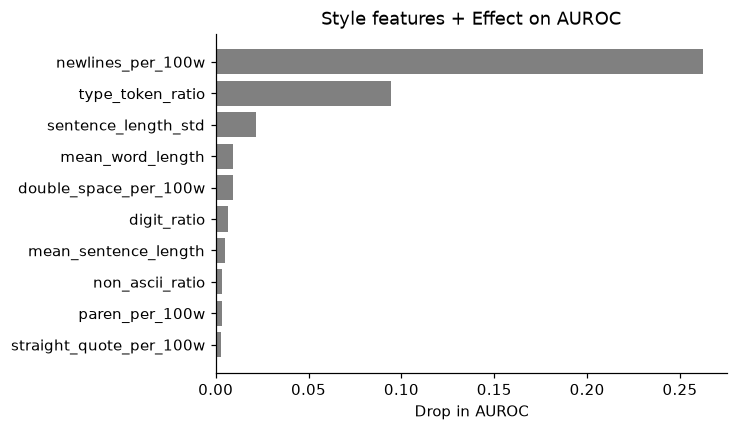

In [8]:
style_train = style_features(train["text"])
drops = []
for train_idx, held_out_idx in LCO_FOLDS:
    trees = make_trees().fit(style_train.iloc[train_idx], y[train_idx])
    drops.append(permutation_importance(trees, style_train.iloc[held_out_idx], y[held_out_idx], scoring="roc_auc",
                                        n_repeats=5, random_state=SEED, n_jobs=-1).importances_mean)
importance = pd.Series(np.mean(drops, axis=0), index=style_train.columns).sort_values().tail(10)

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(importance.index, importance.values, color="gray")
ax.set(xlabel="Drop in AUROC", title="Style features + Effect on AUROC");

We clearly see that newlines or linebreaks mattered most! To figure out why, we can organize our passages by rate of newlines per 100 words into bins and see where AI text is more or less common. Results below:

In [9]:
newline_bins = pd.cut(style_train["newlines_per_100w"], [-0.01, 0, 1, 2, 3, 5, 8, 12, np.inf])
pd.DataFrame({"passages": newline_bins.value_counts().sort_index(), "AI share": train.groupby(newline_bins, observed=True)["label"].mean()})

,passages,AI share
newlines_per_100w,,
"(-0.01, 0.0]",3134,0.444
"(0.0, 1.0]",1160,0.164
"(1.0, 2.0]",622,0.542
"(2.0, 3.0]",714,0.772
"(3.0, 5.0]",1529,0.646
"(5.0, 8.0]",817,0.562
"(8.0, 12.0]",1463,0.357
"(12.0, inf]",561,1.000


As seen above, the share of AI passages at different rates of newline varied, which is likely why linear regression couldn't capture this but trees with cuts at these levels could

**Results:** newline and linebreak usage is a potential giveaway, trees capture it well

## 3. Masking topic

To continue exploring these style differences, we can try hiding the topic so that the model can focus on sentence structure and formatting. To hide the topic, we can replace every word except structural words (the, of, and, I, was, etc.) with `*`, numbers with `#`, and linebreaks with `^`

In [10]:
FUNCTION_WORDS = set(stopwords.words("english"))
TOKEN = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?|\d+|\n|[^\w\s]")

def mask_content(text):
    masked = []
    for tok in TOKEN.findall(text):
        if tok == "\n":
            masked.append("^")
        elif tok[0].isdigit():
            masked.append("#")
        elif tok[0].isalpha():
            masked.append(tok.lower() if tok.lower() in FUNCTION_WORDS else "*")
        else:
            masked.append(tok)
    return " ".join(masked)

def mask_texts(texts):
    return texts.map(mask_content)

example = train["text"].iloc[0]
print(example[:300], "\n")
print(mask_content(example)[:300])

Cipriani S.A. is an Italian hotel and leisure company domiciled in Luxembourg that owns and operates luxury restaurants and clubs around the world including Harry's Bar in Venice and formerly the Rainbow Room in New York City. It specialises in simple, traditional Italian food. Cipriani S.A. traces  

* s . a . is an * * and * * * in * that * and * * * and * * the * * * * in * and * the * * in * * * . it * in * , * * * . * s . a . * its * to * * * * , ( # – # ) who * * * in * in # . ^ * to the * * , * * , a * * , had been * * * in * , where * * was a * . when * * that he was * because his * had *


In [11]:
def make_masked():
    return make_pipeline(
        TfidfVectorizer(token_pattern=r"\S+", lowercase=False, ngram_range=(1, 3), min_df=3, sublinear_tf=True, max_features=200_000),
        LogisticRegression(C=4.0, max_iter=3000),
    )

evaluate("masked n-grams + LR", make_masked, mask_texts)

,random CV,LCO,LCO mean per-cluster,LCO fiction
TF-IDF + LR,0.950,0.908,0.903,0.915
style + LR,0.774,0.654,0.671,0.826
style + gradient boosting,0.990,0.970,0.973,0.993
masked n-grams + LR,0.995,0.988,0.986,0.988


Masking improved performance in all cases except on the fiction passages, where test performance was already very high. We can explore which n-grams were the strongest indicators of AI or human authorship below:

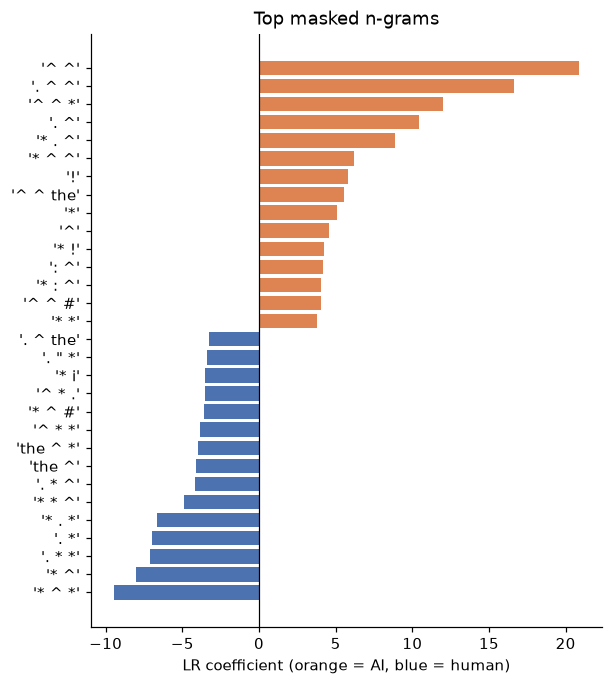

In [12]:
masked_model = make_masked().fit(mask_texts(train["text"]), y)
coefs = pd.Series(masked_model[-1].coef_[0], index=masked_model[0].get_feature_names_out()).sort_values()
top = pd.concat([coefs.head(15), coefs.tail(15)])

fig, ax = plt.subplots(figsize=(6, 7))
ax.barh([f"'{t}'" for t in top.index], top.values, color=np.where(top.values > 0, AI_COLOR, HUMAN_COLOR))
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="LR coefficient (orange = AI, blue = human)", title="Top masked n-grams");

As seen above, newline usage patterns constituted 21 of the top 30 n-grams

**Results:** hiding the topic helped and produced **0.988 LCO**, which is only 0.008 below 5-fold CV

## 4. Exploring linebreaks further

Linebreak style could simply indicate how each source was collected, rather than AI vs human. We can look at how often each format shows up per split:

In [13]:
MID_SENTENCE_BREAK = r"[a-z,]\n[a-z]"
FORMATS = ["blank lines", "single linebreaks only", "no linebreaks"]

def format_group(texts):
    return pd.Series(np.select([texts.str.contains(r"\n\s*\n"), texts.str.contains("\n")], FORMATS[:2], FORMATS[2]),
                     index=texts.index)

def format_rates(texts):
    return pd.concat([format_group(texts).value_counts(normalize=True).reindex(FORMATS) * 100, pd.Series({
        "mid-sentence line break": texts.str.contains(MID_SENTENCE_BREAK).mean() * 100,
        "double space": texts.str.contains("  ").mean() * 100,
    })])

rates = pd.DataFrame({
    "train human %": format_rates(train.loc[y == 0, "text"]),
    "train AI %": format_rates(train.loc[y == 1, "text"]),
    "unlabeled %": format_rates(unlabeled["text"]),
    "test %": format_rates(test["text"]),
})
rates["50/50 train mix %"] = rates[["train human %", "train AI %"]].mean(axis=1)
rates.round(1)

,train human %,train AI %,unlabeled %,test %,50/50 train mix %
blank lines,0.4,66.3,34.6,32.1,33.4
single linebreaks only,64.8,5.9,34.9,31.4,35.3
no linebreaks,34.8,27.8,30.6,36.5,31.3
mid-sentence line break,24.7,0.6,12.8,11.2,12.6
double space,15.1,3.7,8.8,8.9,9.4


Looking at linebreaks and whitespace only:

In [14]:
def format_features(texts):
    n_words = texts.str.split().str.len()
    group = format_group(texts)
    return pd.DataFrame({
        "has_blank_lines": (group == "blank lines").astype(int),
        "single_line_breaks_only": (group == "single linebreaks only").astype(int),
        "newlines_per_100w": texts.str.count("\n") / n_words * 100,
        "mid_sentence_breaks_per_100w": texts.str.count(MID_SENTENCE_BREAK) / n_words * 100,
        "double_space_per_100w": texts.str.count("  ") / n_words * 100,
    })

evaluate("linebreaks only + gradient boosting", make_trees, format_features)

,random CV,LCO,LCO mean per-cluster,LCO fiction
TF-IDF + LR,0.950,0.908,0.903,0.915
style + LR,0.774,0.654,0.671,0.826
style + gradient boosting,0.990,0.970,0.973,0.993
masked n-grams + LR,0.995,0.988,0.986,0.988
linebreaks only + gradient boosting,0.933,0.904,0.932,0.870


And then flattening all whitespace, so the model sees no linebreaks:

In [15]:
def flatten(texts):
    return texts.str.replace(r"\s+", " ", regex=True).str.strip()

FLAT = "masked n-grams, flat + LR"
evaluate(FLAT, make_masked, lambda texts: mask_texts(flatten(texts)))

,random CV,LCO,LCO mean per-cluster,LCO fiction
TF-IDF + LR,0.950,0.908,0.903,0.915
style + LR,0.774,0.654,0.671,0.826
style + gradient boosting,0.990,0.970,0.973,0.993
masked n-grams + LR,0.995,0.988,0.986,0.988
linebreaks only + gradient boosting,0.933,0.904,0.932,0.870
"masked n-grams, flat + LR",0.953,0.901,0.899,0.960


Since the flat model can't see linebreaks, we can use it as a second opinion on a given passage

In [16]:
flat_test = predict_test(FLAT)
test_fiction = (test["cluster"] == FICTION).values

def by_format(df, fiction):
    return [np.where(fiction, "fiction", "other"), format_group(df["text"]).values]

pd.DataFrame({
    "train n": train.groupby(by_format(train, is_fiction)).size(),
    "train AI share": train.groupby(by_format(train, is_fiction))["label"].mean(),
    "train flat P(AI)": pd.Series(oofs[FLAT]).groupby(by_format(train, is_fiction)).mean(),
    "test n": test.groupby(by_format(test, test_fiction)).size(),
    "test flat P(AI)": pd.Series(flat_test).groupby(by_format(test, test_fiction)).mean(),
}).rename_axis(["topic", "format"])

train n  train AI share  train flat P(AI)  \
topic   format                                                              
fiction blank lines                  64           1.000             0.717   
        no linebreaks                78           0.538             0.571   
        single linebreaks only       16           0.188             0.334   
other   blank lines                3271           0.994             0.718   
        no linebreaks              3056           0.442             0.550   
        single linebreaks only     3515           0.083             0.289   

                                test n  test flat P(AI)  
topic   format                                           
fiction blank lines                451            0.530  
        no linebreaks              361            0.429  
        single linebreaks only     273            0.302  
other   blank lines                513            0.750  
        no linebreaks              733            0.432  
        single linebreaks only     669            0.227

In [17]:
# looking at midsentence linebreaks 

mid_sentence_rate = lambda texts: texts.str.contains(MID_SENTENCE_BREAK).mean() * 100
print(f"Fiction passages with a mid-sentence linebreak: train {mid_sentence_rate(train.loc[is_fiction, 'text']):.0f}%, "
      f"test {mid_sentence_rate(test.loc[test_fiction, 'text']):.0f}%")

Fiction passages with a mid-sentence linebreak: train 0%, test 8%


**Results:**
- Line breaks alone was nearly as performant as TF-IDF (0.904 vs 0.908)
- No line breaks was simular, but strong on fiction (0.960 vs 0.915)
- On the test set, both signals agree outside fiction, but a lot of fiction might be poetry and thus does not fit either well

## 5. Comparing models by cluster

In [18]:
comparison = pd.DataFrame(results).T
comparison.insert(1, "drop to LCO", comparison["random CV"] - comparison["LCO"])
comparison.sort_values("LCO", ascending=False)

,random CV,drop to LCO,LCO,LCO mean per-cluster,LCO fiction
masked n-grams + LR,0.995,0.008,0.988,0.986,0.988
style + gradient boosting,0.990,0.020,0.970,0.973,0.993
TF-IDF + LR,0.950,0.042,0.908,0.903,0.915
linebreaks only + gradient boosting,0.933,0.029,0.904,0.932,0.870
"masked n-grams, flat + LR",0.953,0.051,0.901,0.899,0.960
style + LR,0.774,0.119,0.654,0.671,0.826


Per cluster AUROC:

In [19]:
terms = cluster_vec.get_feature_names_out()
all_clusters = np.concatenate(list(cluster_ids.values()))

def top_terms(c, n=4):
    centroid = np.asarray(tfidf_all[all_clusters == c].mean(axis=0)).ravel()
    return ", ".join(terms[centroid.argsort()[::-1][:n]])

per_cluster = pd.DataFrame({
    name: [roc_auc_score(y[train["cluster"] == c], oof[train["cluster"] == c]) for c in range(N_CLUSTERS)]
    for name, oof in oofs.items()
})
per_cluster.insert(0, "test %", test_share * 100)
per_cluster.insert(0, "top terms", [top_terms(c) for c in range(N_CLUSTERS)])
per_cluster.round(3)

,top terms,test %,TF-IDF + LR,style + LR,style + gradient boosting,masked n-grams + LR,linebreaks only + gradient boosting,"masked n-grams, flat + LR"
0,"segmentation, image, images, method",7.067,0.899,0.153,0.993,0.998,0.999,0.878
1,"like, just, ve, don",13.767,0.897,0.848,0.978,0.976,0.791,0.903
2,"film, movie, br, story",4.067,0.892,0.699,0.923,0.950,0.887,0.841
3,"pepper, cup, salt, oil",7.233,0.986,0.940,0.989,0.998,0.984,0.976
4,"sugar, cup, flour, butter",4.567,0.986,0.974,0.989,0.999,0.987,0.982
5,"said, year, company, mr",6.200,0.868,0.730,0.985,0.993,0.970,0.904
6,"paper, study, results, quantum",6.300,0.923,0.370,0.952,0.993,0.976,0.909
7,"team, league, game, club",2.967,0.821,0.576,0.966,0.986,0.954,0.804
8,"born, university, american, known",11.667,0.848,0.594,0.964,0.978,0.897,0.838
9,"love, life, world, man",36.167,0.915,0.826,0.993,0.988,0.870,0.960


**Results:** masked n-grams are the best overall and close to the best in every cluster

## 6. First submision

We can pick the model with the best LCO (masked n-grams + LR) and refit it on all of train. We also save the flat model, so comparing both on the leaderboard shows whether the line-break signal holds up on test data

In [20]:
chosen = max(results, key=lambda n: (round(results[n]["LCO"], 3), results[n]["LCO fiction"]))
print("Chosen model:", chosen)

sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
SUBMISSION_DIR.mkdir(exist_ok=True)

for name, preds in [(chosen, predict_test(chosen)), (FLAT, flat_test)]:
    submission = pd.DataFrame({"id": test["id"], "label": preds})
    assert len(submission) == 3000 and submission["id"].equals(sample_submission["id"])
    assert submission["label"].between(0, 1).all()
    path = SUBMISSION_DIR / f"02_{re.sub(r'[^a-z0-9]+', '_', name.lower().replace('+', 'plus')).strip('_')}.csv"
    submission.to_csv(path, index=False)
    print(f"Wrote {path}  ({(preds > 0.5).mean():.0%} of test predicted AI)")

Chosen model: masked n-grams + LR
Wrote ../submissions/02_masked_n_grams_plus_lr.csv  (43% of test predicted AI)
Wrote ../submissions/02_masked_n_grams_flat_plus_lr.csv  (41% of test predicted AI)


## TLDR

1. Trees capture info from style features much better than linear regression
2. Masking the passage topic gave our best model
3. Most of that improvement came from linebreaks. Generally, we use single linebreaks while AI uses blank lines between paragraphs. This might be largely influenced by where our data came from though
4. Test set seems to follow the same pattern, except in fiction which has different formatting
5. Even without linebreaks, just looking at structure words and punctuation can match TF-IDF and do better on fiction

**Results**:
Masked n-grams scored 0.943, flatten n-grams scored 0.847